# What house prices follow

Where Mecklenburg's assessed values sit in the space of house and location features, seen four ways:

- **PCA**: the directions along which houses differ most, whatever their price. Does price follow them?
- **UMAP**: a nonlinear map of the same features, which keeps neighbors together. Which kinds of houses and
  which areas form groups, and how price runs across them?
- **PLS** (partial least squares): the one direction in feature space that tracks price best, and what it is
  made of.
- **The map and the calendar**: price per sq ft by location, and sale prices since 2016 against Zillow's index.

**Data.** `data/features/properties_features.csv` (run `uv run python -m src.pipeline.run --to features`
first), one row per parcel (the 1,931 parcels listed twice are counted once). Price here is the county's
**2023 assessed value** (`total_value`), which every house has; the last section uses recorded **sale prices**,
which only sold houses have. The notebook runs in about a minute.

**Features.** The 22 a buyer can see: 6 about the house (type, size, bedrooms, bathrooms, lot, year built) and 16
about its location (latitude
and longitude, distances to schools, emergency services and light rail, nearby places, school scores, crime,
floodplain). Left out: the neighborhood price, its sale count and `price_momentum`, which are computed from sale
prices and would put price into the axes, and `area`, which is only used to color the plots. Lot size, size and
the counts and distances are log-transformed first, since they have long right tails; then every feature is
standardized, so each counts equally, and capped at 5 standard deviations, so the few extreme houses (lots of
hundreds of acres, for example) don't stretch the axes.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm, imported by umap
warnings.filterwarnings("ignore", message="n_jobs value", category=UserWarning)  # umap: one thread with a seed

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.patheffects import withStroke
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator
from sklearn.compose import ColumnTransformer
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

from src.components.market_estimate import MIN_PRICE_PER_SQFT
from src.utils.common import read_dataframe, resolve_path
from src.utils.load_config import load_config

# reference palette, as in area_effect.ipynb: one blue ramp for magnitude, categorical slots in fixed
# order (the first three validate for every pair), gray for context. Figures sit on the light chart
# surface, so they read the same in a dark-themed notebook.
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
CONTEXT = "#d6d5cf"
PRICE = LinearSegmentedColormap.from_list(
    "price", ["#b7d3f6", "#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]
)
DENSITY = LinearSegmentedColormap.from_list("density", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
HALO = [withStroke(linewidth=3, foreground=SURFACE)]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": MUTED, "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False,
})


def dollars(value, _=None):
    if value == 0:
        return "$0"
    return f"${value / 1e6:g}M" if value >= 1e6 else f"${value / 1e3:,.0f}k"


def value_colorbar(fig, mappable, ax, label):
    """A colorbar for a LogNorm of dollar values, with round dollar ticks."""
    bar = fig.colorbar(mappable, ax=ax, label=label, fraction=0.05, pad=0.02)
    low, high = mappable.norm.vmin, mappable.norm.vmax
    ticks = [t for t in [150e3, 200e3, 300e3, 400e3, 600e3, 800e3, 1e6, 1.5e6, 2e6, 3e6] if low <= t <= high]
    bar.ax.yaxis.set_major_locator(FixedLocator(ticks))
    bar.ax.yaxis.set_minor_locator(NullLocator())
    bar.ax.yaxis.set_major_formatter(FuncFormatter(dollars))
    bar.outline.set_visible(False)
    return bar


def bare(ax):
    """UMAP's axes have no units: no ticks, grid or spines."""
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)

In [2]:
cfg = load_config()
houses = read_dataframe(resolve_path(cfg, "features_data"), "properties_features.csv")
houses = houses[houses["total_value"].gt(0) & houses["heated_area"].gt(0)]
houses = houses.drop_duplicates("parcel_id").reset_index(drop=True)
houses["value_per_sqft"] = houses["total_value"] / houses["heated_area"]

SKEWED = ["acreage", "heated_area", "places_count", "education_nearest_miles", "emergency_fire_miles",
          "emergency_police_miles", "emergency_medical_miles", "light_rail_miles"]
PLAIN = ["year_built", "bedrooms", "bathrooms", "latitude", "longitude", "health_care_share", "activity_share",
         "elementary_school_score", "middle_school_score", "high_school_score", "violent_crime_rate",
         "property_crime_rate", "in_floodplain"]
prep = ColumnTransformer([
    ("log", make_pipeline(SimpleImputer(strategy="median"),
                          FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), SKEWED),
    ("plain", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), PLAIN),
    ("type", OneHotEncoder(sparse_output=False), ["land_use_class"]),
])
X = prep.fit_transform(houses)
numeric = len(SKEWED) + len(PLAIN)  # the type columns are 0/1 and come last
print(f"capped at 5 standard deviations: {(np.abs(X[:, :numeric]) > 5).sum():,} values "
      f"in {(np.abs(X[:, :numeric]) > 5).any(axis=1).sum():,} houses")
X[:, :numeric] = np.clip(X[:, :numeric], -5, 5)
LABELS = {
    "acreage": "lot size", "heated_area": "heated area", "places_count": "places within 5 miles",
    "education_nearest_miles": "distance to nearest school", "emergency_fire_miles": "distance to fire station",
    "emergency_police_miles": "distance to police station", "emergency_medical_miles": "distance to emergency room",
    "light_rail_miles": "distance to light rail", "year_built": "year built", "latitude": "latitude (north)",
    "longitude": "longitude (east)", "health_care_share": "health care share of places",
    "activity_share": "activity share of places", "elementary_school_score": "elementary school score",
    "middle_school_score": "middle school score", "high_school_score": "high school score",
    "violent_crime_rate": "violent crime rate", "property_crime_rate": "property crime rate",
    "in_floodplain": "in floodplain", "land_use_class_single_family": "type: single family",
    "land_use_class_townhouse": "type: townhouse", "land_use_class_condo": "type: condo",
}
names = [LABELS.get(name.split("__", 1)[1], name.split("__", 1)[1]) for name in prep.get_feature_names_out()]
log_value = np.log(houses["total_value"].to_numpy())
value_norm = LogNorm(*np.percentile(houses["total_value"], [2, 98]))  # one color scale for every price plot

# the scatter plots and UMAP use the same 30,000 houses, drawn at random
sample = np.random.default_rng(0).choice(len(houses), 30_000, replace=False)
sampled = houses.iloc[sample].reset_index(drop=True)
print(f"{len(houses):,} houses x {X.shape[1]} columns; median assessed value ${houses['total_value'].median():,.0f}")

capped at 5 standard deviations: 7,047 values in 6,250 houses
302,242 houses x 24 columns; median assessed value $391,400


## 1. PCA: the main directions houses differ in

PCA finds the directions of greatest variation in the standardized features, without looking at price. If price
follows one of them, that direction is a summary of what goes with expensive houses.

variance explained: PC1 23%, PC2 16%, PC3 10%, PC4 8% (first two: 39%)
correlation with log assessed value: PC1 +0.62, PC2 +0.31, PC3 +0.37, PC4 +0.23


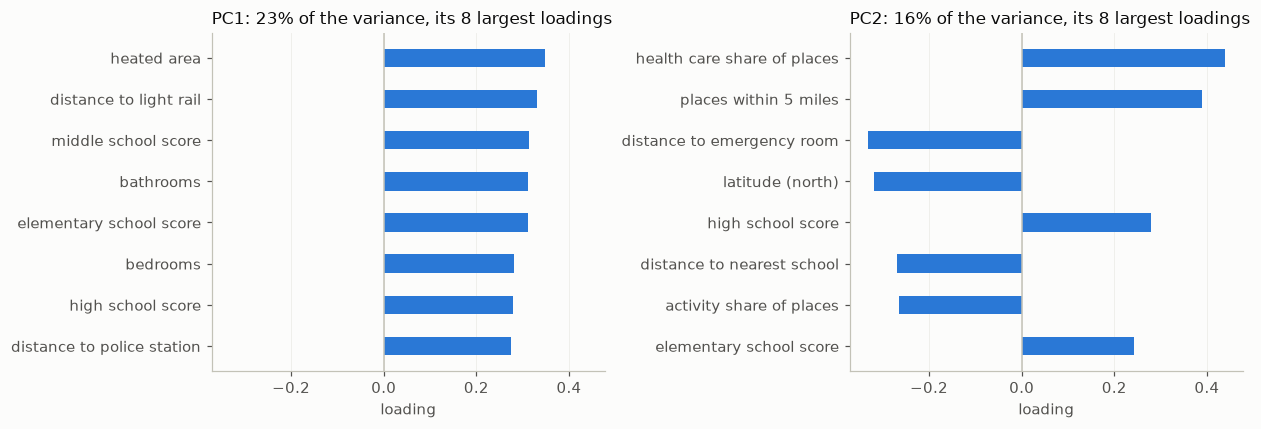

In [3]:
pca = PCA(n_components=10, random_state=0).fit(X)
pcs = pca.transform(X)
share = pca.explained_variance_ratio_
print("variance explained:", ", ".join(f"PC{k + 1} {s:.0%}" for k, s in enumerate(share[:4])),
      f"(first two: {share[:2].sum():.0%})")
print("correlation with log assessed value:",
      ", ".join(f"PC{k + 1} {np.corrcoef(pcs[:, k], log_value)[0, 1]:+.2f}" for k in range(4)))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4), sharex=True)
for k, ax in enumerate(axes):
    loading = pd.Series(pca.components_[k], index=names)
    top = loading[loading.abs().sort_values().index[-8:]]
    ax.barh(top.index, top.to_numpy(), color=SERIES[0], height=0.45)
    ax.axvline(0, color="#c3c2b7", linewidth=1)
    ax.grid(axis="y", visible=False)
    ax.set(title=f"PC{k + 1}: {share[k]:.0%} of the variance, its 8 largest loadings", xlabel="loading")
fig.tight_layout()

**PC1 (23% of the variance) is a suburban axis:** bigger houses with more bathrooms and bedrooms, better school scores, and farther from light rail and police stations. **PC2 (16%) is mostly how built-up the surroundings are, and how far south:** more places nearby and a larger share of them health care, closer to an emergency room and a school, and farther south (latitude loads negatively).

median assessed value by PC1 decile: $254k, $294k, $306k, $337k, $358k, $390k, $429k, $477k, $544k, $719k


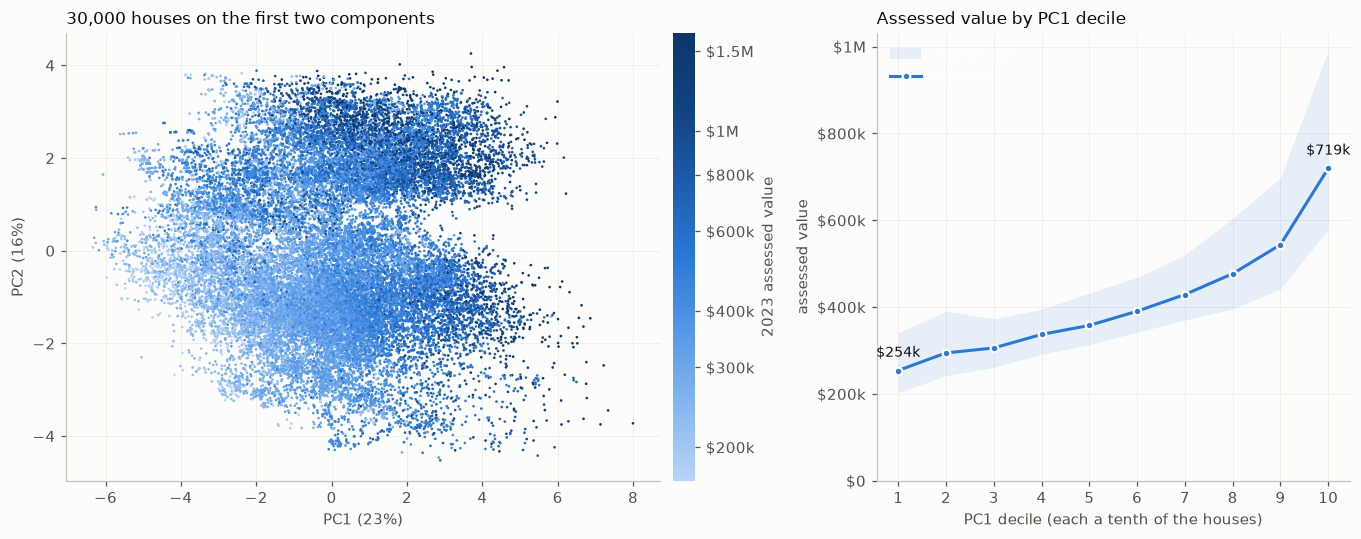

In [4]:
fig, (ax, trend) = plt.subplots(1, 2, figsize=(12.5, 5), gridspec_kw={"width_ratios": [1.35, 1]})
order = np.random.default_rng(1).permutation(len(sample))  # random drawing order, so no price sits on top
points = ax.scatter(pcs[sample[order], 0], pcs[sample[order], 1], c=sampled["total_value"].to_numpy()[order],
                    cmap=PRICE, norm=value_norm, s=3, linewidths=0, rasterized=True)
value_colorbar(fig, points, ax, "2023 assessed value")
ax.set(xlabel=f"PC1 ({share[0]:.0%})", ylabel=f"PC2 ({share[1]:.0%})",
       title="30,000 houses on the first two components")

decile = pd.qcut(pcs[:, 0], 10, labels=False) + 1
by_decile = houses.groupby(decile)["total_value"].quantile([0.25, 0.5, 0.75]).unstack()
trend.fill_between(by_decile.index, by_decile[0.25], by_decile[0.75], color=SERIES[0], alpha=0.1, linewidth=0,
                   label="middle half")
trend.plot(by_decile.index, by_decile[0.5], color=SERIES[0], linewidth=2, marker="o", markersize=5,
           markeredgecolor=SURFACE, markeredgewidth=1.5, label="median")
for d in [1, 10]:
    trend.annotate(dollars(by_decile.loc[d, 0.5]), (d, by_decile.loc[d, 0.5]), xytext=(0, 9),
                   textcoords="offset points", ha="center", color=INK, fontsize=9)
trend.yaxis.set_major_formatter(FuncFormatter(dollars))
trend.set(xticks=range(1, 11), xlabel="PC1 decile (each a tenth of the houses)", ylabel="assessed value",
          title="Assessed value by PC1 decile", ylim=(0, None))
trend.legend(loc="upper left")
fig.tight_layout()
print("median assessed value by PC1 decile:", ", ".join(dollars(v) for v in by_decile[0.5]))

**Price follows PC1** (correlation +0.62 with log assessed value). The median rises with every decile, from $254k in the lowest tenth to $719k in the highest, 2.8 times as much, and the middle half widens at the top. PC2 adds a second, weaker gradient (+0.31): at the same PC1, the upper band is darker. The two components hold 39% of the variance, so much of what sets houses apart lies outside this view.

## 2. UMAP: groups of similar houses

UMAP places each house near the houses most like it across all 22 features, so groups that PCA's straight axes
blend together come apart. Distances between groups and the axes themselves mean little; what counts is which
houses land together. It runs on the 30,000-house sample (about 30 seconds).

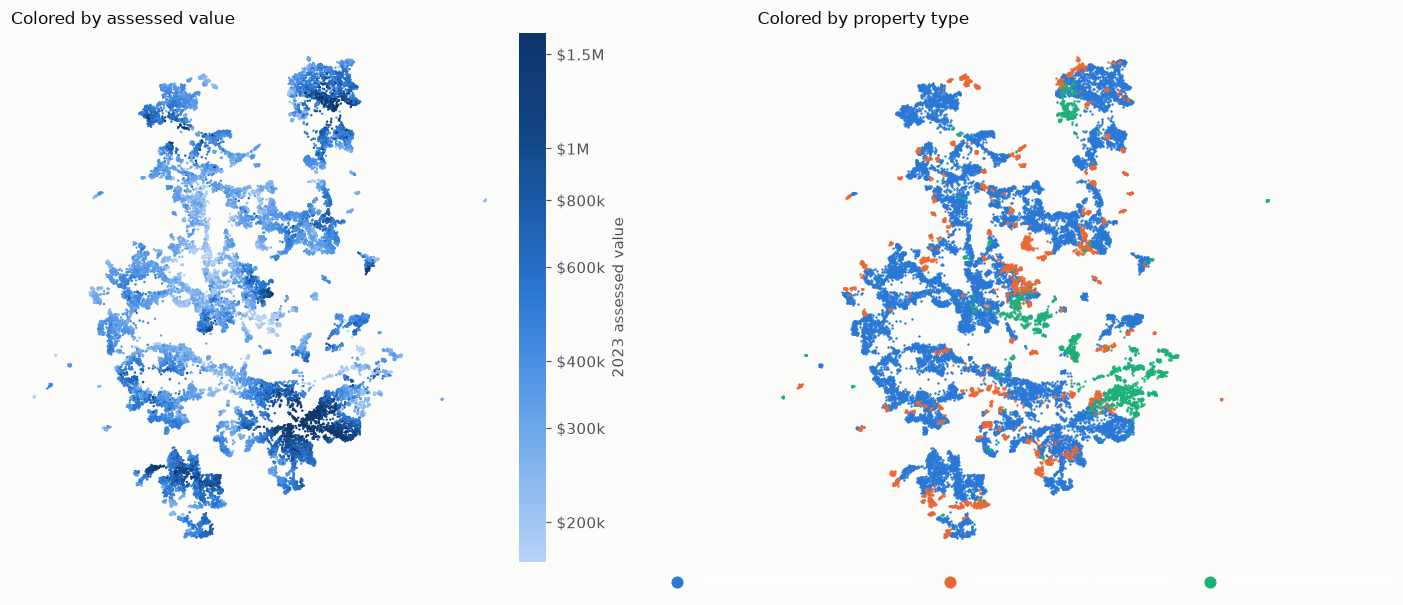

In [5]:
# 100 neighbors rather than the default 15: with fewer, school zones and neighborhoods break into many small
# islands and the price gradient between them is lost
embedding = umap.UMAP(n_neighbors=100, min_dist=0.5, random_state=0, n_jobs=1).fit_transform(X[sample])

fig, (by_value, by_type) = plt.subplots(1, 2, figsize=(13, 5.6))
points = by_value.scatter(*embedding[order].T, c=sampled["total_value"].to_numpy()[order], cmap=PRICE,
                          norm=value_norm, s=2.5, linewidths=0, rasterized=True)
value_colorbar(fig, points, by_value, "2023 assessed value")
by_value.set_title("Colored by assessed value")

TYPES = ["single_family", "townhouse", "condo"]
for color, kind in zip(SERIES, TYPES):
    mine = (sampled["land_use_class"] == kind).to_numpy()
    by_type.scatter(*embedding[mine].T, color=color, s=2.5, linewidths=0, rasterized=True,
                    label=f"{kind.replace('_', ' ')} ({mine.mean():.0%} of houses)")
by_type.legend(loc="upper center", bbox_to_anchor=(0.5, 0), ncol=3, markerscale=5, fontsize=9)
by_type.set_title("Colored by property type")
for ax in (by_value, by_type):
    bare(ax)
fig.tight_layout()

**Expensive houses gather in a few large groups** toward the edges of the map; the cheapest sit toward the middle. Condos and townhouses don't form one group of their own: they sit in pockets inside the single-family groups around them, since 16 of the 22 features describe the location, and a condo shares those with its neighbors, not with condos elsewhere.

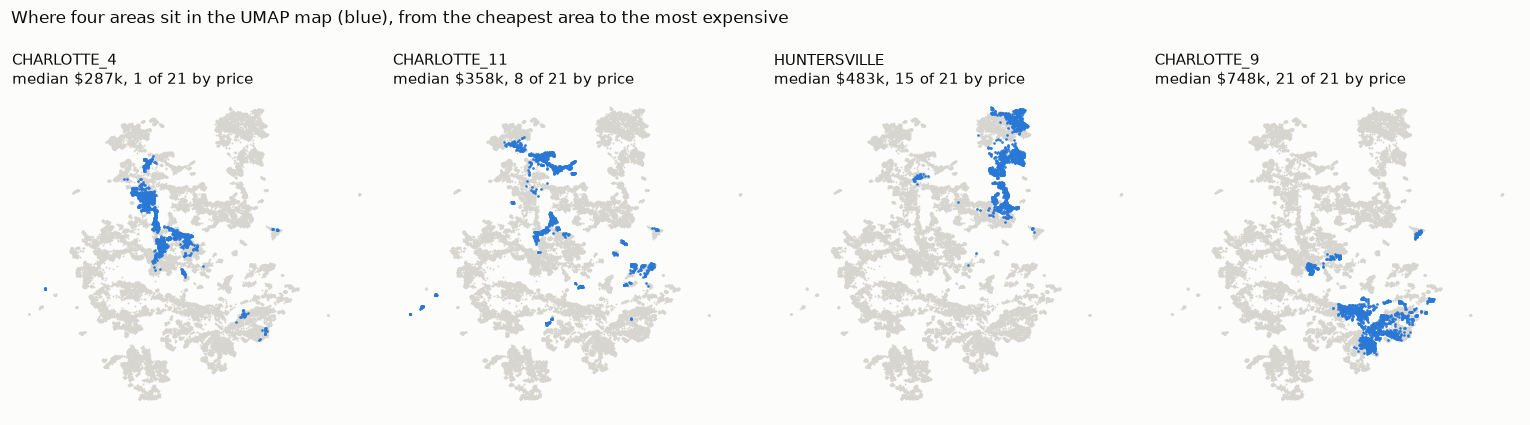

In [6]:
area_median = houses.groupby("area")["total_value"].median().sort_values()
picks = area_median.index[[0, len(area_median) // 3, 2 * len(area_median) // 3, -1]]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.9))
for ax, area in zip(axes, picks):
    mine = (sampled["area"] == area).to_numpy()
    ax.scatter(*embedding[~mine].T, color=CONTEXT, s=1.5, linewidths=0, rasterized=True)
    ax.scatter(*embedding[mine].T, color=SERIES[0], s=3, linewidths=0, rasterized=True)
    rank = area_median.index.get_loc(area) + 1
    ax.set_title(f"{area}\nmedian {dollars(area_median[area])}, {rank} of {len(area_median)} by price", fontsize=10)
    bare(ax)
fig.suptitle("Where four areas sit in the UMAP map (blue), from the cheapest area to the most expensive",
             x=0.01, ha="left", color=INK, fontsize=11)
fig.tight_layout()

**Each area holds its own part of the map, though `area` wasn't one of the features.** The cheapest area (CHARLOTTE_4) sits in the cheap middle, the most expensive (CHARLOTTE_9) makes up most of one of the large expensive groups, and Huntersville forms a group of its own. The location features alone place a house in its area, which fits the README's finding that the model is almost as accurate without the neighborhood price.

## 3. PLS: the direction that tracks price

PCA ignores price; PLS looks for the direction in the same standardized features whose scores covary most with
log assessed value. Its first component is the best single-number summary of "how expensive this kind of house in
this kind of place is", and its weights say what that summary is made of.

share of the variation in log assessed value explained: one component 64%, two 75%


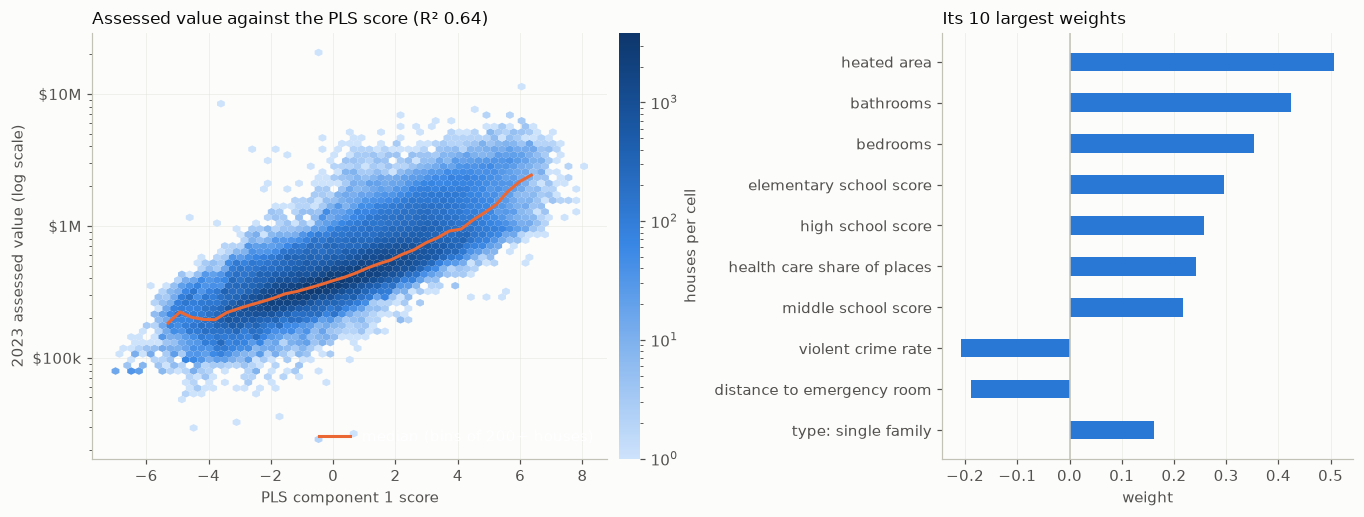

In [7]:
pls = PLSRegression(n_components=1).fit(X, log_value)
score = pls.transform(X)[:, 0]
r2_one = r2_score(log_value, pls.predict(X).ravel())
r2_two = r2_score(log_value, PLSRegression(n_components=2).fit(X, log_value).predict(X).ravel())
print(f"share of the variation in log assessed value explained: one component {r2_one:.0%}, two {r2_two:.0%}")

fig, (ax, weights_ax) = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={"width_ratios": [1.35, 1]})
cells = ax.hexbin(score, houses["total_value"], gridsize=60, yscale="log", bins="log", mincnt=1, cmap=DENSITY,
                  linewidths=0)
bins = pd.cut(score, 40)
per_bin = houses["total_value"].groupby(bins, observed=True).agg(["median", "size"])
per_bin = per_bin[per_bin["size"] >= 200]  # the sparse ends are noise
ax.plot([b.mid for b in per_bin.index], per_bin["median"], color=SERIES[1], linewidth=2,
        label="median (bins of 200+ houses)")
ax.yaxis.set_major_formatter(FuncFormatter(dollars))
ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
ax.set(xlabel="PLS component 1 score", ylabel="2023 assessed value (log scale)",
       title=f"Assessed value against the PLS score (R\u00b2 {r2_one:.2f})")
ax.legend(loc="lower right")
density_bar = fig.colorbar(cells, ax=ax, label="houses per cell", fraction=0.05, pad=0.02)
density_bar.outline.set_visible(False)

weight = pd.Series(pls.x_weights_[:, 0], index=names)
top = weight[weight.abs().sort_values().index[-10:]]
weights_ax.barh(top.index, top.to_numpy(), color=SERIES[0], height=0.45)
weights_ax.axvline(0, color="#c3c2b7", linewidth=1)
weights_ax.grid(axis="y", visible=False)
weights_ax.set(title="Its 10 largest weights", xlabel="weight")
fig.tight_layout()

**One direction explains 64% of the variation in log assessed value** (two explain 75%), against 36% for PC1 (its correlation of 0.60, squared): the features hold much of the price, but not along the direction in which they vary most. The weights rank what goes with a higher value: size first (heated area, bathrooms, bedrooms), then school scores and a larger health-care share of nearby places, against violent crime and distance to an emergency room. Features that move together share their weight, so the ranking is of groups more than of single features. On the log scale the median line is close to straight through the middle, so each step along the score adds about the same percentage, and it steepens at the top.

## 4. Where: price per sq ft on the map

Assessed value per heated sq ft takes house size out of the price, which leaves mostly location. Each hexagon is
the median of the houses in it (at least 5). Charlotte's parts are labeled C1 to C15, numbered north to south as
in `data_preprocessing.assign_area`.

median value per sq ft, lowest areas: CHARLOTTE_2 $175, CHARLOTTE_1 $176, CHARLOTTE_3 $180
median value per sq ft, highest areas: CHARLOTTE_9 $302, CHARLOTTE_8 $321, CHARLOTTE_7 $325


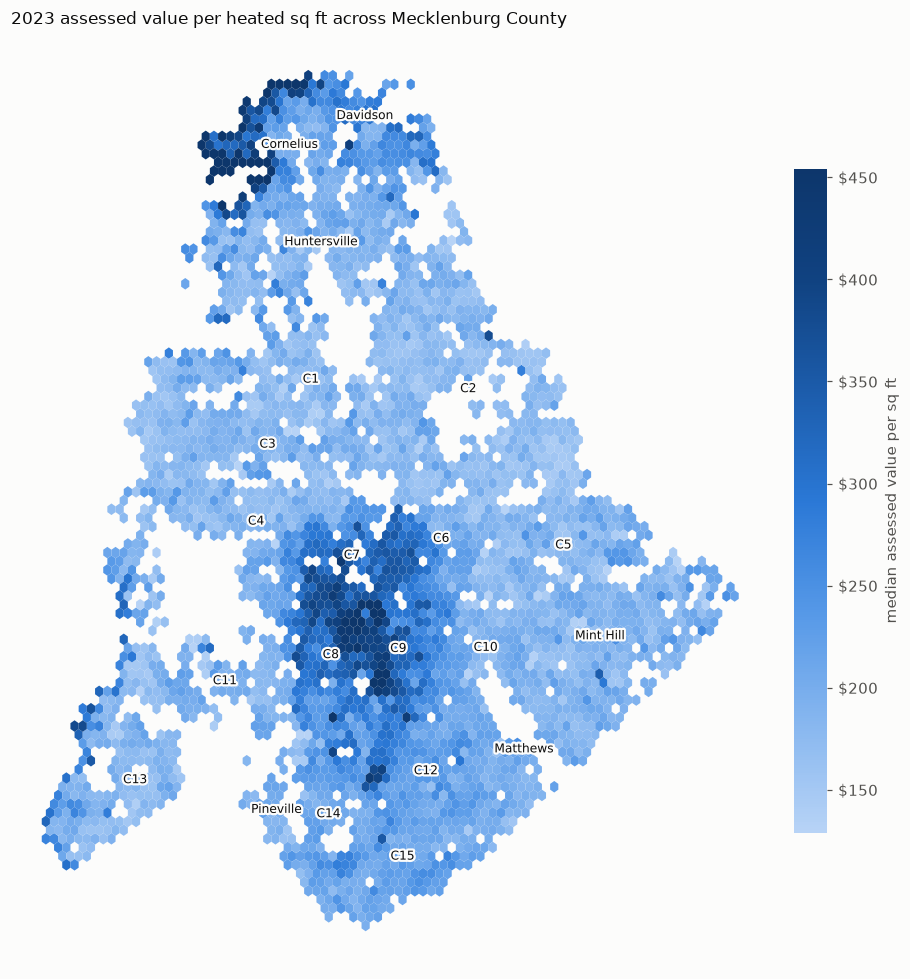

In [8]:
low, high = np.percentile(houses["value_per_sqft"], [2, 98])
fig, ax = plt.subplots(figsize=(8.5, 9))
cells = ax.hexbin(houses["longitude"], houses["latitude"], C=houses["value_per_sqft"], reduce_C_function=np.median,
                  gridsize=85, mincnt=5, cmap=PRICE, vmin=low, vmax=high, linewidths=0)
ax.set_aspect(1 / np.cos(np.radians(houses["latitude"].mean())))  # a degree of longitude is narrower
for area, (lon, lat) in houses.groupby("area")[["longitude", "latitude"]].median().iterrows():
    label = area.replace("CHARLOTTE_", "C") if area.startswith("CHARLOTTE") else area.title()
    ax.text(lon, lat, label, ha="center", va="center", fontsize=8, color=INK, path_effects=HALO)
bar = fig.colorbar(cells, ax=ax, label="median assessed value per sq ft", fraction=0.04, pad=0.02,
                   format=FuncFormatter(lambda v, _: f"${v:,.0f}"))
bar.outline.set_visible(False)
bare(ax)
ax.set_title("2023 assessed value per heated sq ft across Mecklenburg County")
fig.tight_layout()
by_area = houses.groupby("area")["value_per_sqft"].median().sort_values()
print("median value per sq ft, lowest areas:", ", ".join(f"{a} ${v:,.0f}" for a, v in by_area.head(3).items()))
print("median value per sq ft, highest areas:", ", ".join(f"{a} ${v:,.0f}" for a, v in by_area.tail(3).items()))

**Price per sq ft is highest in a band through the middle south of Charlotte** (C7, C8 and C9, medians $302 to $325 a sq ft, with C6 next to them) **and along Lake Norman** in Cornelius and Davidson. It is lowest in the north and west of Charlotte, C1 to C3 ($175 to $180), a little over half the price of the band. The southern parts (C12, C14, C15), Matthews and Mint Hill sit in between.

## 5. When: sale prices since 2016

The assessed value is one date (January 2023), so the trend over time comes from recorded arms-length sales
(the county's "Qualified" sales, at least $50 per sq ft, as in `market_estimate.load_sales`). Each house carries
only its most recent sale, so the early years have fewer sales, and only of houses that haven't sold since. As a
check, the median sale price per sq ft is set beside Zillow's home value index for the county, which is built
from repeat sales; both are indexed to their 2016 average.

median sale price per sq ft: 2019 126, 2022 196, latest quarter 217 (2026Q3)
Zillow home value index, Mecklenburg: 2019 125, 2022 193, latest quarter 200 (2026Q3)


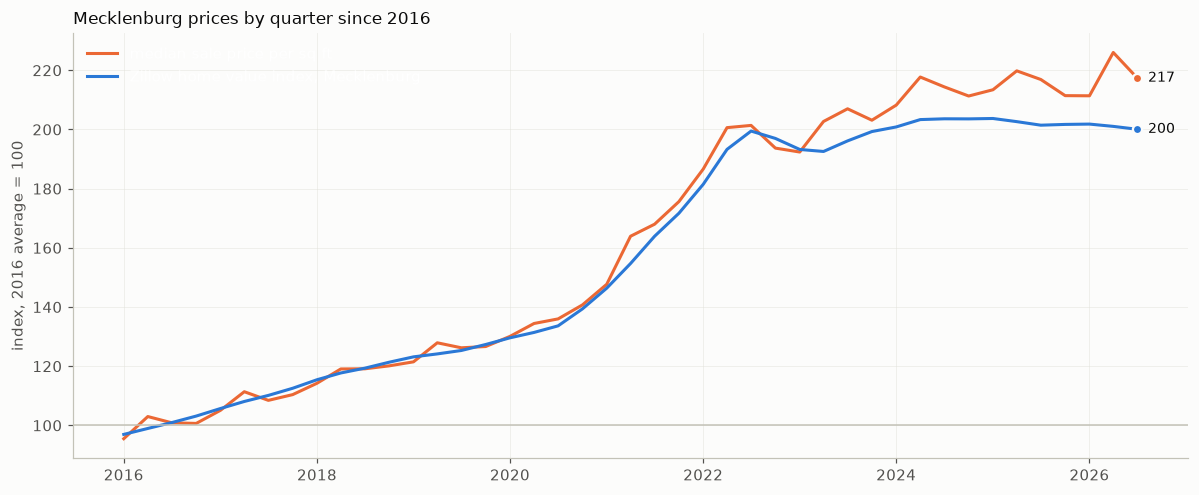

In [9]:
sales = houses[houses["arms_length_sale"].astype(bool) & houses["price_per_sqft"].ge(MIN_PRICE_PER_SQFT)].copy()
sales["sale_date"] = pd.to_datetime(sales["sale_date"], format="mixed")
sales = sales[sales["sale_date"] <= pd.Timestamp.today()]
quarter = sales["sale_date"].dt.to_period("Q")
quarterly = sales.groupby(quarter)["price_per_sqft"].median()

zhvi = pd.read_csv(resolve_path(cfg, "raw_data") + "zillow/county_zhvi.csv")
row = zhvi[(zhvi["RegionName"] == "Mecklenburg County") & (zhvi["State"] == "NC")].iloc[0]
zillow = pd.Series({pd.Timestamp(c): row[c] for c in zhvi.columns if c[:4].isdigit()})
zillow = zillow.groupby(zillow.index.to_period("Q")).mean()
zillow = zillow[(zillow.index >= quarterly.index.min()) & (zillow.index <= quarterly.index.max())]


def indexed(series):
    return series / series[series.index.year == 2016].mean() * 100


fig, ax = plt.subplots(figsize=(11, 4.6))
lines = [("median sale price per sq ft", indexed(quarterly), SERIES[1]),
         ("Zillow home value index, Mecklenburg", indexed(zillow), SERIES[0])]
for label, series, color in lines:
    x = series.index.to_timestamp()
    ax.plot(x, series.to_numpy(), color=color, linewidth=2, label=label)
    ax.plot(x[-1], series.iloc[-1], "o", color=color, markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5)
    ax.annotate(f"{series.iloc[-1]:.0f}", (x[-1], series.iloc[-1]), xytext=(7, 0), textcoords="offset points",
                va="center", color=INK, fontsize=9)
ax.axhline(100, color="#c3c2b7", linewidth=1)
ax.set(ylabel="index, 2016 average = 100", title="Mecklenburg prices by quarter since 2016")
ax.legend(loc="upper left")
fig.tight_layout()
for label, series, _ in lines:
    yearly = series.groupby(series.index.year).mean()
    print(f"{label}: 2019 {yearly[2019]:.0f}, 2022 {yearly[2022]:.0f}, latest quarter {series.iloc[-1]:.0f} "
          f"({series.index[-1]})")

land_use_class  single family  townhouse  condo
sale_date                                      
2016                      108        107    169
2017                      117        115    171
2018                      128        124    196
2019                      135        138    204
2020                      145        148    223
2021                      177        175    254
2022                      214        206    280
2023                      220        212    300
2024                      233        222    326
2025                      237        222    310
2026                      246        217    289
change since 2016: single family +128%, townhouse +102%, condo +71% (2026 is the latest year, 7,067 sales so far)


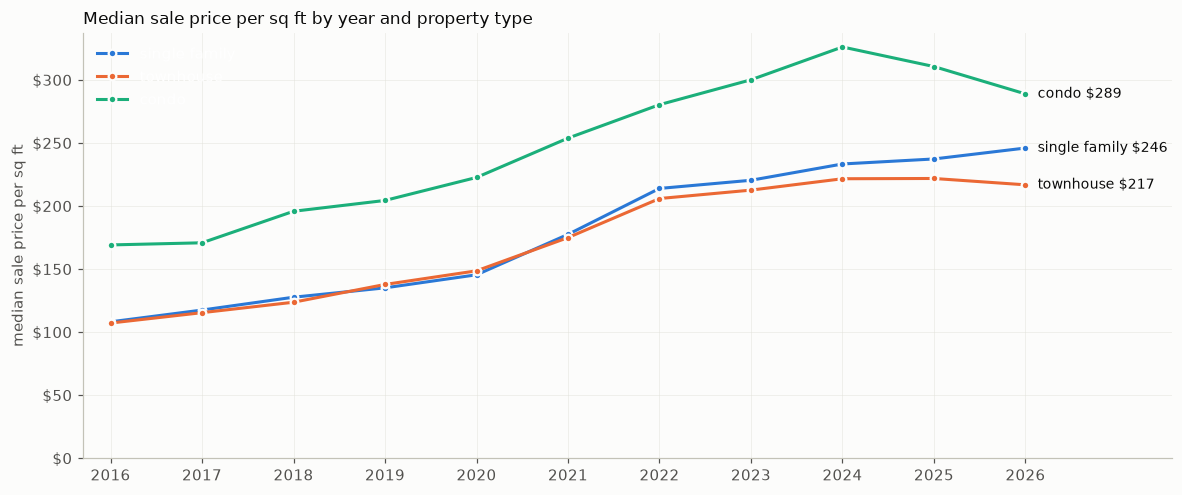

In [10]:
yearly = sales.groupby([sales["sale_date"].dt.year, "land_use_class"])["price_per_sqft"].median().unstack()[TYPES]
counts = sales.groupby([sales["sale_date"].dt.year, "land_use_class"]).size().unstack()[TYPES]

fig, ax = plt.subplots(figsize=(11, 4.6))
for color, kind in zip(SERIES, TYPES):
    ax.plot(yearly.index, yearly[kind], color=color, linewidth=2, marker="o", markersize=5,
            markeredgecolor=SURFACE, markeredgewidth=1.5, label=kind.replace("_", " "))
    ax.annotate(f"{kind.replace('_', ' ')} ${yearly[kind].iloc[-1]:,.0f}", (yearly.index[-1], yearly[kind].iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", color=INK, fontsize=9)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set(xticks=yearly.index, xlim=(yearly.index[0] - 0.3, yearly.index[-1] + 1.6), ylim=(0, None),
       ylabel="median sale price per sq ft", title="Median sale price per sq ft by year and property type")
ax.legend(loc="upper left")
fig.tight_layout()
print(yearly.round(0).astype(int).rename(columns=lambda k: k.replace("_", " ")).to_string())  # the chart as a table
growth = yearly.iloc[-1] / yearly.loc[2016] - 1
print("change since 2016:", ", ".join(f"{k.replace('_', ' ')} {growth[k]:+.0%}" for k in TYPES),
      f"({yearly.index[-1]} is the latest year, {counts.iloc[-1].sum():,} sales so far)")

**Prices per sq ft about doubled since 2016, and rose fastest in 2021 and 2022.** The median sale and Zillow's index agree until 2023 (2022: 196 and 193); since then the median sale has pulled ahead, to 217 against Zillow's 200 in the latest quarter. Part of that gap is likely the last-sale effect above: recent quarters hold every house that sold, while earlier ones lose the houses that have sold again since.

**By type**, single-family houses rose the most (+128% per sq ft since 2016, $108 to $246) and are still rising. Townhouses (+102%) have been flat since 2024 ($222, then $217). Condos, the most expensive per sq ft, rose least (+71%) and have fallen from their 2024 peak, $326 to $289. 2026 covers January to August only.

## What the trend is

- **Size and schools carry the price; location sets its level.** The direction that tracks price best (PLS, 64% of the variation) is mostly size and school scores, against crime. The direction houses vary most (PCA's PC1) is a suburban one, and price follows it: from $254k in its lowest tenth to $719k in its highest.
- **The market is a set of local groups.** UMAP separates the areas and puts the expensive houses in a few large groups; condos and townhouses sit with the houses around them, not with each other.
- **On the map,** price per sq ft is highest through C7 to C9 and along Lake Norman, and lowest in north and west Charlotte, at a little over half.
- **Over time,** prices per sq ft about doubled since 2016, mostly in 2021 and 2022, and have since flattened by Zillow's index. Single-family houses are still rising; condos have fallen since 2024.

The embeddings use the 2023 assessed value and today's features; they describe how prices are spread, not why. The model and its SHAP explanation (`shap_explain.ipynb`, `report.md`) measure what each feature adds.